<a href="https://colab.research.google.com/github/jsa-12/Python-project/blob/main/Python_project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving Fuel_Level_Part_1-1.csv to Fuel_Level_Part_1-1.csv
Saving Fuel_Level_Part_2-1.csv to Fuel_Level_Part_2-1.csv
Saving Invoices-1.csv to Invoices-1.csv
Saving Locations-1.csv to Locations-1.csv
Saving Tanks-1.csv to Tanks-1.csv


In [ ]:
locations = pd.read_csv("Locations-1.csv")
tanks = pd.read_csv("Tanks-1.csv")
invoices = pd.read_csv("Invoices-1.csv")

fuel_1 = pd.read_csv("Fuel_Level_Part_1-1.csv")
fuel_2 = pd.read_csv("Fuel_Level_Part_2-1.csv")


In [ ]:
#We are renaming the "Fuel Level" and "Time stamp" columns to make it the same names from "fuel_1" and "fuel_2"

fuel_2 = fuel_2.rename(columns=
           {
              "Fuel_Level": "Fuel Level",
              "Timestamp": "Time stamp"
           }
)

#Then combining the 2 dataset together
fuel_levels = pd.concat([fuel_1, fuel_2], ignore_index=True)
fuel_levels


,Tank ID,Fuel Level,Time stamp
0,T 12,27161.0,1/1/2017 0:10
1,T 12,27017.0,1/1/2017 0:25
2,T 12,26934.0,1/1/2017 0:40
3,T12,NaN,1/1/2017 0:45
4,T 12,26786.0,1/1/2017 0:55
...,...,...,...
1859655,T 32,27619.0,8/15/2019 23:53
1859656,T 22,31548.0,8/15/2019 23:57
1859657,T 16,53492.0,8/15/2019 23:57
1859658,T 18,27081.0,8/15/2019 23:57


In [ ]:
#Parse dates and timestamps

fuel_levels["Time stamp"] = pd.to_datetime(
    fuel_levels["Time stamp"],
    errors = "coerce"
)
fuel_levels.dtypes

,0
Tank ID,object
Fuel Level,float64
Time stamp,datetime64[ns]


In [ ]:
#Checking how many missing values in each column
fuel_levels.isna().sum()

,0
Tank ID,0
Fuel Level,2
Time stamp,0


In [ ]:
#Identify rows with missing fuel level values
fuel_levels[fuel_levels["Fuel Level"].isna()]


,Tank ID,Fuel Level,Time stamp


In [ ]:
#Checking how many duplicated in each column
fuel_levels.duplicated().sum()

np.int64(71)

In [ ]:
fuel_levels[fuel_levels.duplicated()]

,Tank ID,Fuel Level,Time stamp
68323,T 12,32809.0,2019-02-04 13:59:00
68825,T 12,17012.0,2019-02-09 17:59:00
68986,T 12,31238.0,2019-02-11 09:59:00
69392,T 12,32775.0,2019-02-15 13:59:00
69601,T 12,24655.0,2019-02-17 17:59:00
...,...,...,...
1671971,T 22,26994.0,2019-02-25 06:58:00
1678564,T 10,26294.0,2019-03-03 01:59:00
1689919,T 10,13700.0,2019-03-15 03:00:00
1790656,T 18,35913.0,2019-06-14 15:13:00


In [ ]:
# Remove missing fuel measurements
fuel_levels = fuel_levels.dropna(subset=["Fuel Level"])

# Remove duplicate rows
fuel_levels = fuel_levels.drop_duplicates()
fuel_levels

,Tank ID,Fuel Level,Time stamp
0,T 12,27161.0,2017-01-01 00:10:00
1,T 12,27017.0,2017-01-01 00:25:00
2,T 12,26934.0,2017-01-01 00:40:00
4,T 12,26786.0,2017-01-01 00:55:00
5,T 12,26748.0,2017-01-01 01:10:00
...,...,...,...
1859655,T 32,27619.0,2019-08-15 23:53:00
1859656,T 22,31548.0,2019-08-15 23:57:00
1859657,T 16,53492.0,2019-08-15 23:57:00
1859658,T 18,27081.0,2019-08-15 23:57:00


In [ ]:
# Check the column names in the tanks dataset
tanks.columns

Index(['Tank ID', 'Tank Location', 'Tank Number', 'Tank Type',
       'Tank Capacity'],
      dtype='object')

In [ ]:
#Finding Tank IDs that do not exist in the tanks dataset

invalid_tanks = fuel_levels [

      ~fuel_levels["Tank ID"].isin(tanks["Tank ID"])
]
print(f"Records with invalid Tank IDs: " , len(invalid_tanks))
print(f"Invalid Tank IDs: " , invalid_tanks["Tank ID"].unique())


Records with invalid Tank IDs:  0
Invalid Tank IDs:  []


In [ ]:
#Checking for negative fuel levels

negative_fuel = fuel_levels[fuel_levels["Fuel Level"] < 0]
print(f"Records with negative fuel records: " , len(negative_fuel))


Records with negative fuel records:  0


In [ ]:
#Matching each fuel record with its tank capacity

fuel_capacity = fuel_levels.merge(

      tanks[["Tank ID", "Tank Capacity"]],
      on="Tank ID",
      how="left"
)

#Checking for fuel levels exceeding tank capacity

over_capacity = fuel_capacity[

     fuel_capacity["Fuel Level"] > fuel_capacity["Tank Capacity"]
]

print(f"records exceeding tank capacity: " , len(over_capacity))

records exceeding tank capacity:  0


I began my process by merging the two fuel-level datasets, bringing the total number of recorded instances to 1,859,660. However, before combining them, I made sure that the columns in both fuel-level datasets had the same names and that the timestamps were converted to the datetime type so that further analysis could be conducted.

I then checked the records for any missing values and found two records with missing fuel levels, which I proceeded to remove from the dataset. I did the same for the 71 duplicate records I found, bringing the total number of records in the dataset down to 1,859,587.

Following this, I checked the Tank IDs against the tanks dataset to make sure that all Tank IDs matched and found that there were no mismatched Tank IDs. I also checked for any cases of negative fuel levels or fuel levels exceeding tank capacity and found no problems in either area.

In [ ]:
#Linking fuel levels with tank information using Tank ID

fuel_tanks = fuel_levels.merge(

       tanks,
       on="Tank ID",
       how="left",
       validate="many_to_one"
)

print(f"Records before merging: " , len(fuel_levels))
print(f"Records after merging: " , len(fuel_tanks))
print(f"Columns: " , fuel_tanks.columns.tolist())

Records before merging:  1859587
Records after merging:  1859587
Columns:  ['Tank ID', 'Fuel Level', 'Time stamp', 'Tank Location', 'Tank Number', 'Tank Type', 'Tank Capacity']


In [ ]:
#Linking tank information to gas station locations

fuel_stations = fuel_tanks.merge(

       locations,
       left_on="Tank Location",
       right_on="Gas Station Location",
       how="left",
       validate="many_to_one"
)

print(f"Records beofore merging: " , len(fuel_tanks))
print(f"Records after merging: " , len(fuel_stations))
print(f"Columns: " , fuel_stations.columns.tolist())


Records beofore merging:  1859587
Records after merging:  1859587
Columns:  ['Tank ID', 'Fuel Level', 'Time stamp', 'Tank Location', 'Tank Number', 'Tank Type', 'Tank Capacity', 'Gas Station Location', 'Gas Station Name', 'Gas Station Address', 'Gas Station Latitude', 'Gas Station Longitude']


In [ ]:
#Checking fuel type values in both datasets
print(f"Tank types: " , fuel_stations["Tank Type"].unique())
print(f"Invoice fuel types: " , invoices["Fuel Type"].unique())

Tank types:  ['U' 'D' 'P']
Invoice fuel types:  ['G' 'D' nan]


In [ ]:
#Matchinging tank types with invoice fuel types
fuel_stations["Fuel Type"] = fuel_stations["Tank Type"].map({
    "D": "D",
    "U": "G",
    "P": "X"
})

# Checking the new fuel type values
print(fuel_stations[["Tank Type", "Fuel Type"]].drop_duplicates())


       Tank Type Fuel Type
885126         U         G
0              D         D
83788          P         X


In [ ]:
#Checking missing fuel types in the invoices dataset
missing_fuel_types = invoices["Fuel Type"].isna().sum()

print("Missing invoice fuel types:", missing_fuel_types)


Missing invoice fuel types: 42


In [ ]:
#Displaying invoices with missing fuel types
missing_invoices = invoices[invoices["Fuel Type"].isna()]

missing_invoices.head(10)


,Invoice Date,Invoice ID,Invoice Gas Station Location,Gross Purchase Cost,Amount Purchased,Fuel Type
2,1/2/2017,10002.0,1,NaN,NaN,NaN
4,1/2/2017,NaN,2,NaN,NaN,NaN
19,1/5/2017,NaN,1,NaN,NaN,NaN
33,1/9/2017,NaN,1,NaN,NaN,NaN
60,1/17/2017,NaN,3,NaN,NaN,NaN
128,2/8/2017,NaN,2,NaN,NaN,NaN
178,2/24/2017,NaN,1,NaN,NaN,NaN
205,3/6/2017,NaN,5,NaN,NaN,NaN
239,3/15/2017,NaN,4,NaN,NaN,NaN
293,4/4/2017,NaN,2,NaN,NaN,NaN


In [ ]:
#Checking missing values in the invoices dataset
print(invoices.isna().sum())


Invoice Date                     0
Invoice ID                      41
Invoice Gas Station Location     0
Gross Purchase Cost             42
Amount Purchased                42
Fuel Type                       42
dtype: int64


In [ ]:
#Removing invoices with missing purchase information
invoices_clean = invoices.dropna(
    subset=["Gross Purchase Cost", "Amount Purchased", "Fuel Type"]
).copy()

#Checking the results after cleaning
print("Invoices before cleaning:", len(invoices))
print("Invoices after cleaning:", len(invoices_clean))
print("Missing values after cleaning:")
print(invoices_clean.isna().sum())


Invoices before cleaning: 2873
Invoices after cleaning: 2831
Missing values after cleaning:
Invoice Date                    0
Invoice ID                      0
Invoice Gas Station Location    0
Gross Purchase Cost             0
Amount Purchased                0
Fuel Type                       0
dtype: int64


In [ ]:
#Summarizing invoices by station and fuel type
invoice_summary = invoices_clean.groupby(
    ["Invoice Gas Station Location", "Fuel Type"]
).agg(
    Total_Purchased=("Amount Purchased", "sum"),
    Total_Cost=("Gross Purchase Cost", "sum"),
    Number_of_Orders=("Invoice ID", "count")
).reset_index()

print(invoice_summary.to_string(index=False))


 Invoice Gas Station Location Fuel Type  Total_Purchased   Total_Cost  Number_of_Orders
                            1         D      4872458.032 5.896560e+06               599
                            1         G     10866211.216 1.230239e+07               762
                            2         D      3460899.808 4.015548e+06               347
                            2         G      2822513.776 3.040002e+06               285
                            3         D       431815.120 4.929777e+05                41
                            3         G       423518.656 4.473295e+05                39
                            4         D      1632468.432 1.967561e+06               184
                            4         G      1578617.776 1.730773e+06               172
                            5         D       811733.952 9.946808e+05               125
                            5         G      1346712.816 1.487689e+06               155
                            6   

In [ ]:
#Linking invoice summary to station information
station_invoice_summary = invoice_summary.merge(
    locations[["Gas Station Location", "Gas Station Name"]],
    left_on="Invoice Gas Station Location",
    right_on="Gas Station Location",
    how="left",
    validate="many_to_one"
)

#Checking that the merge did not duplicate records
print("Records before merging:", len(invoice_summary))
print("Records after merging:", len(station_invoice_summary))

#Checking that purchase totals did not change
print("Purchased quantities unchanged:",
      invoice_summary["Total_Purchased"].sum() ==
      station_invoice_summary["Total_Purchased"].sum())

print("Purchase costs unchanged:",
      invoice_summary["Total_Cost"].sum() ==
      station_invoice_summary["Total_Cost"].sum())


Records before merging: 16
Records after merging: 16
Purchased quantities unchanged: True
Purchase costs unchanged: True


In [ ]:
#Checking for duplicate invoice records
print("Duplicate records:", invoices_clean.duplicated().sum())

#Checking for repeated invoice IDs
print("Repeated invoice IDs:",
      invoices_clean["Invoice ID"].duplicated().sum())


Duplicate records: 0
Repeated invoice IDs: 0


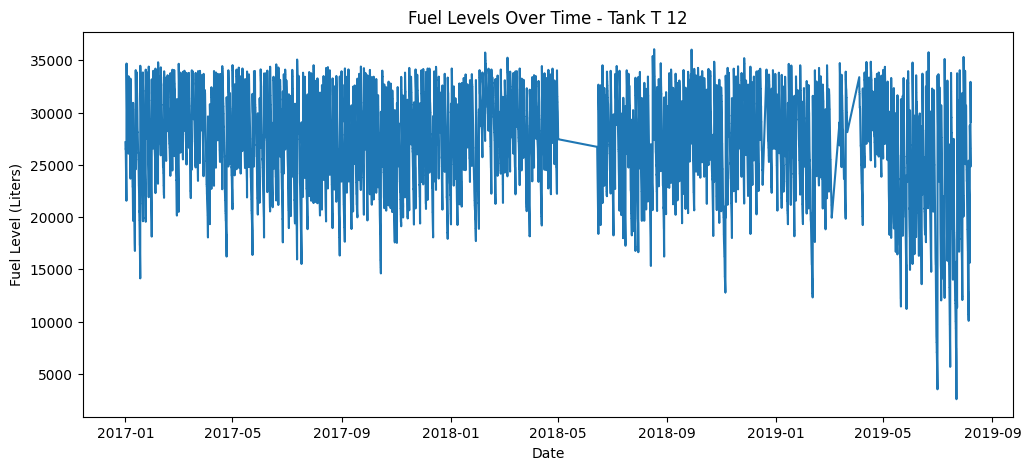

In [ ]:
import matplotlib.pyplot as plt

# Selecting fuel level records for Tank T 12
tank_12 = fuel_stations[fuel_stations["Tank ID"] == "T 12"]

# Sorting records by timestamp
tank_12 = tank_12.sort_values("Time stamp")

# Ploting fuel levels over time
plt.figure(figsize=(12, 5))
plt.plot(tank_12["Time stamp"], tank_12["Fuel Level"])

plt.title("Fuel Levels Over Time - Tank T 12")
plt.xlabel("Date")
plt.ylabel("Fuel Level (Liters)")
plt.show()



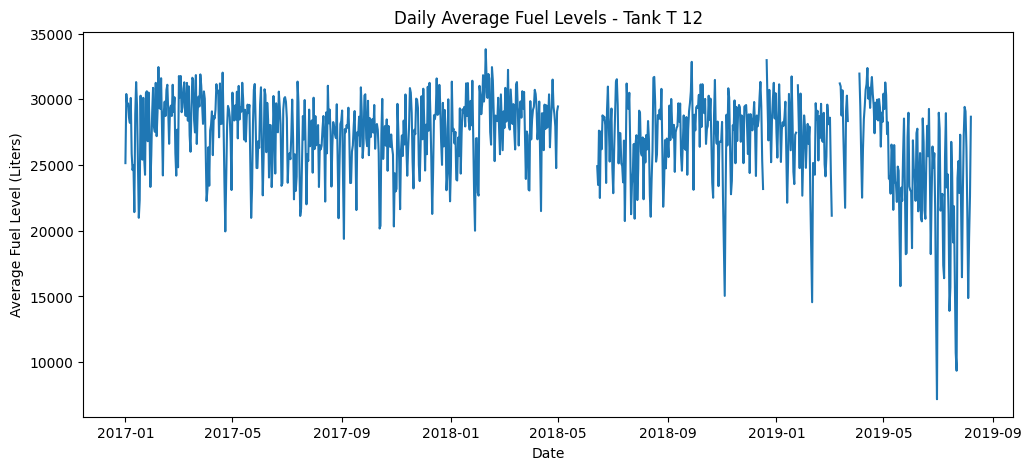

In [ ]:
#Calculate daily average fuel levels for Tank T 12
tank_12_daily = tank_12.set_index("Time stamp")["Fuel Level"].resample("D").mean()

# Plot daily average fuel levels
plt.figure(figsize=(12, 5))
plt.plot(tank_12_daily.index, tank_12_daily.values)

plt.title("Daily Average Fuel Levels - Tank T 12")
plt.xlabel("Date")
plt.ylabel("Average Fuel Level (Liters)")
plt.show()


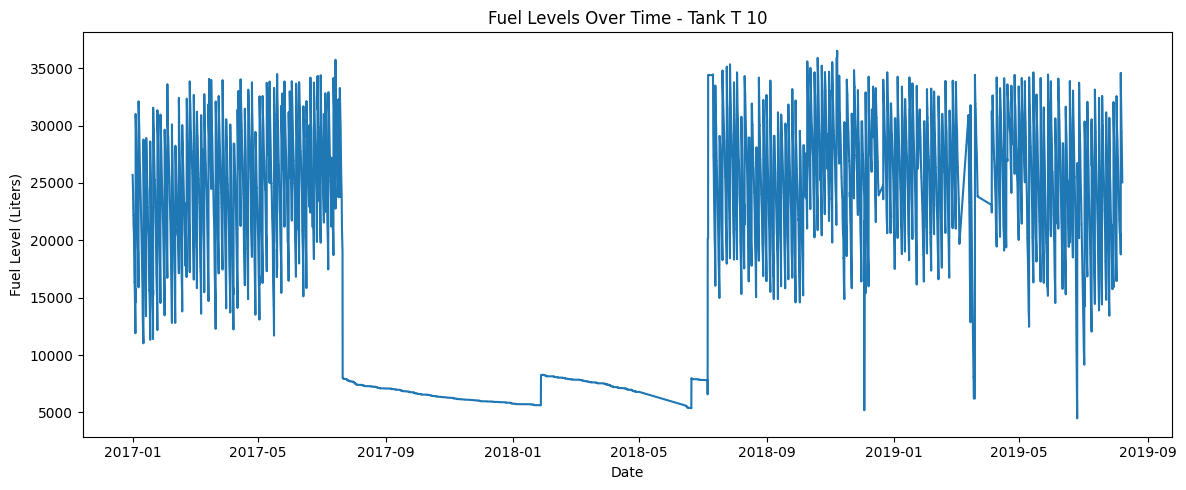

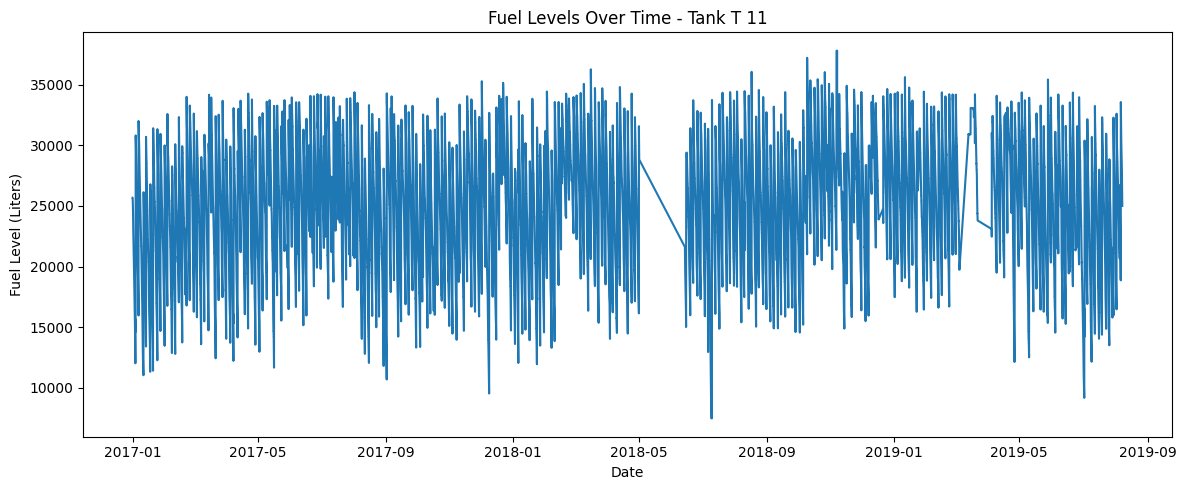

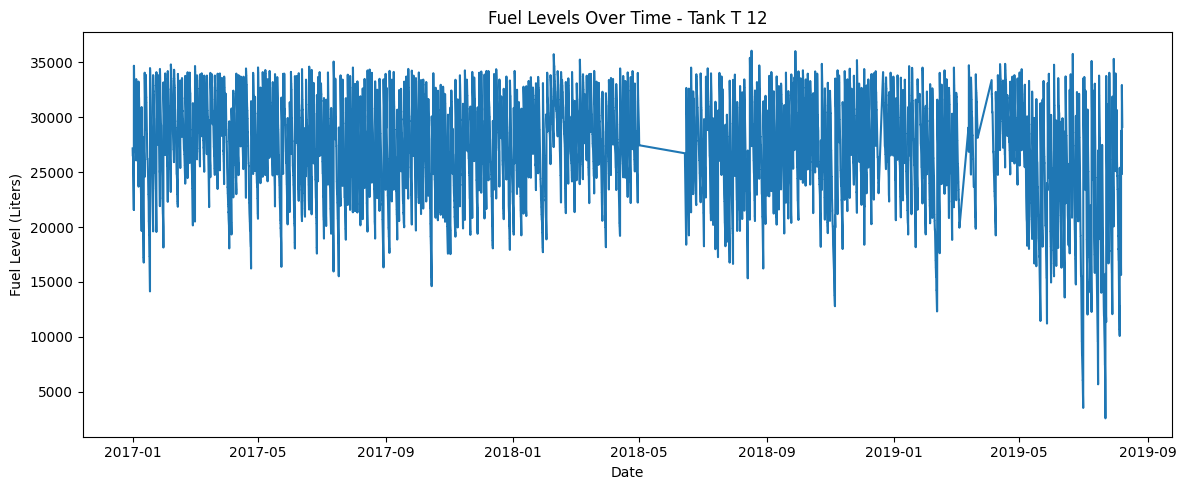

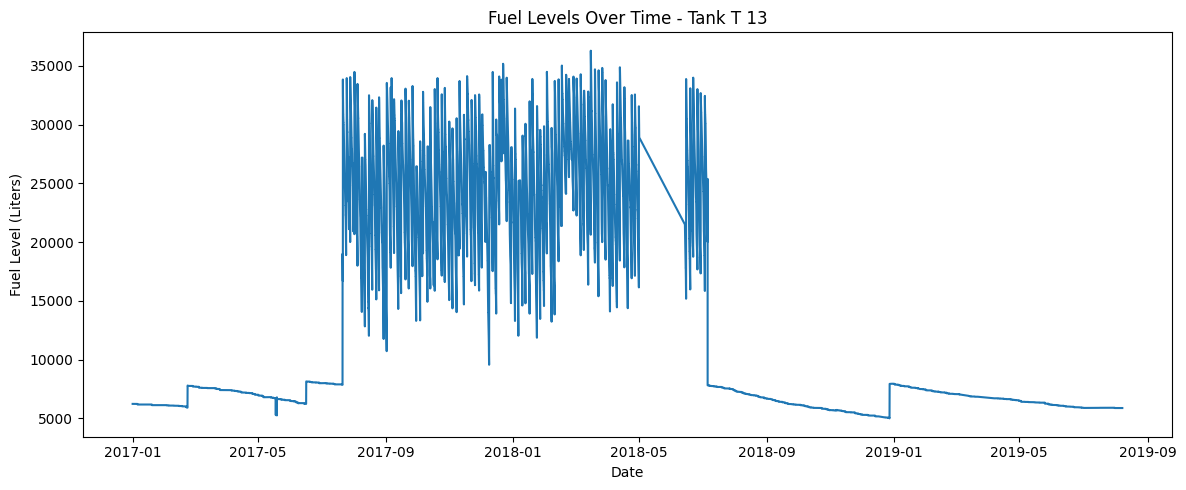

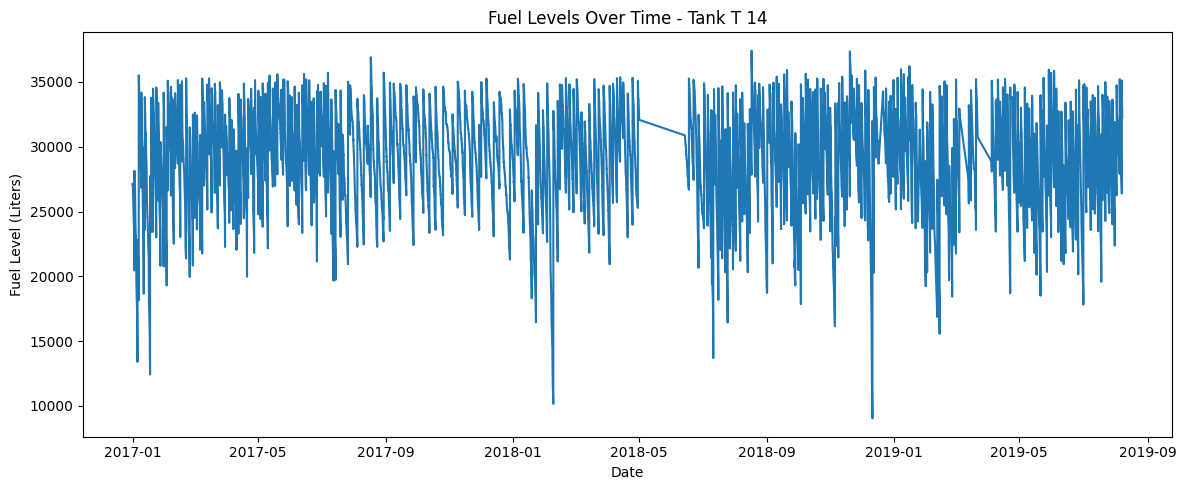

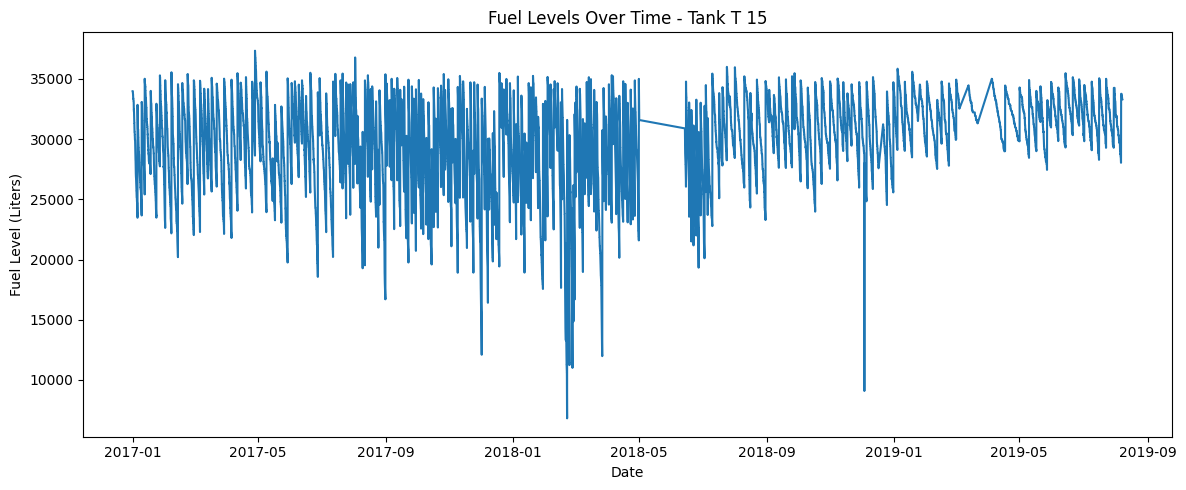

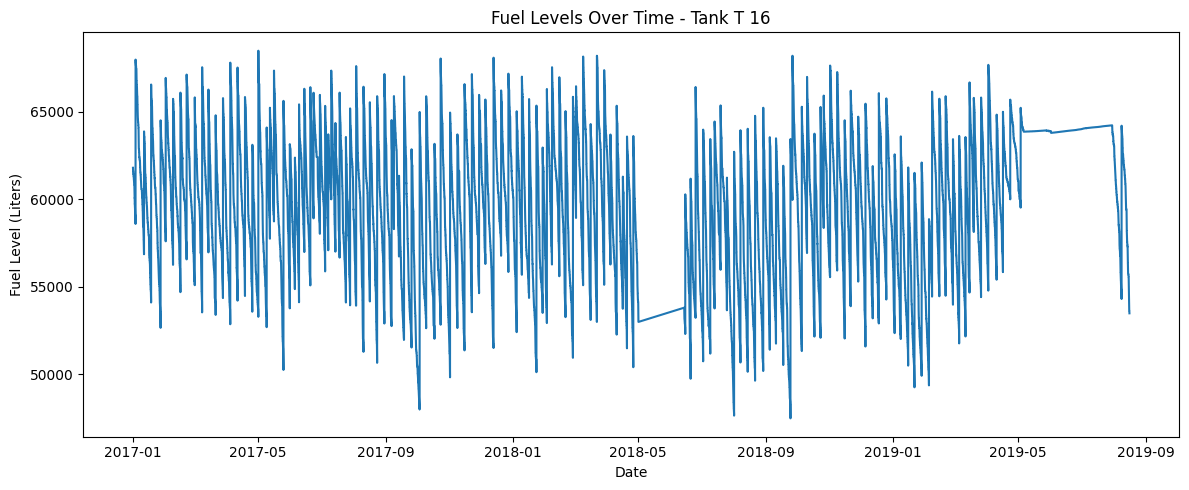

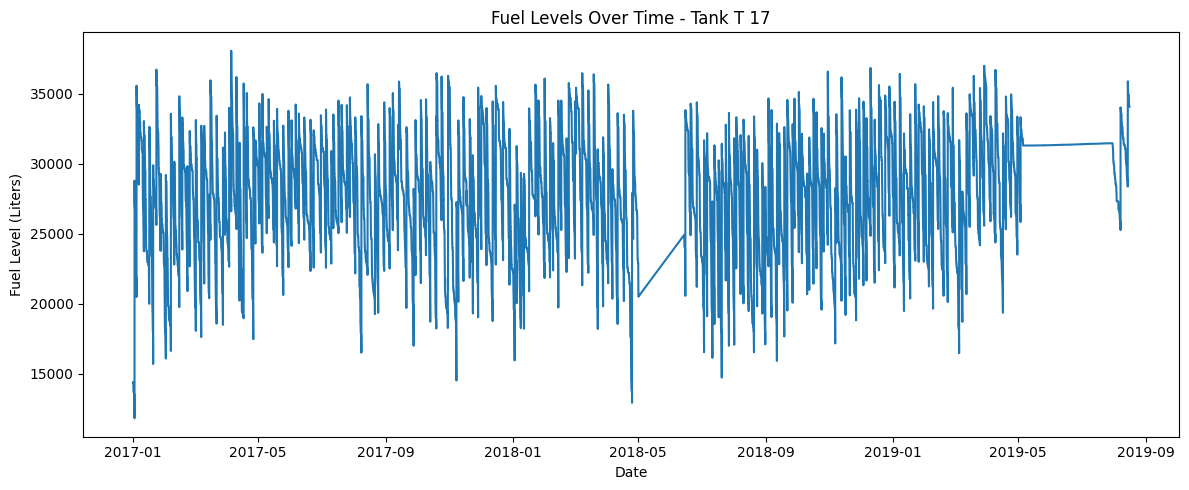

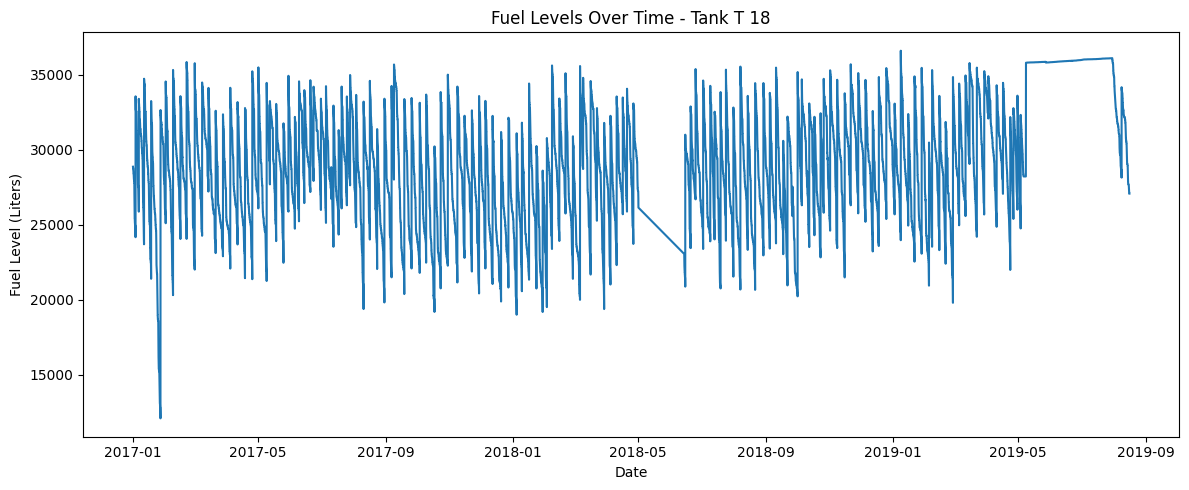

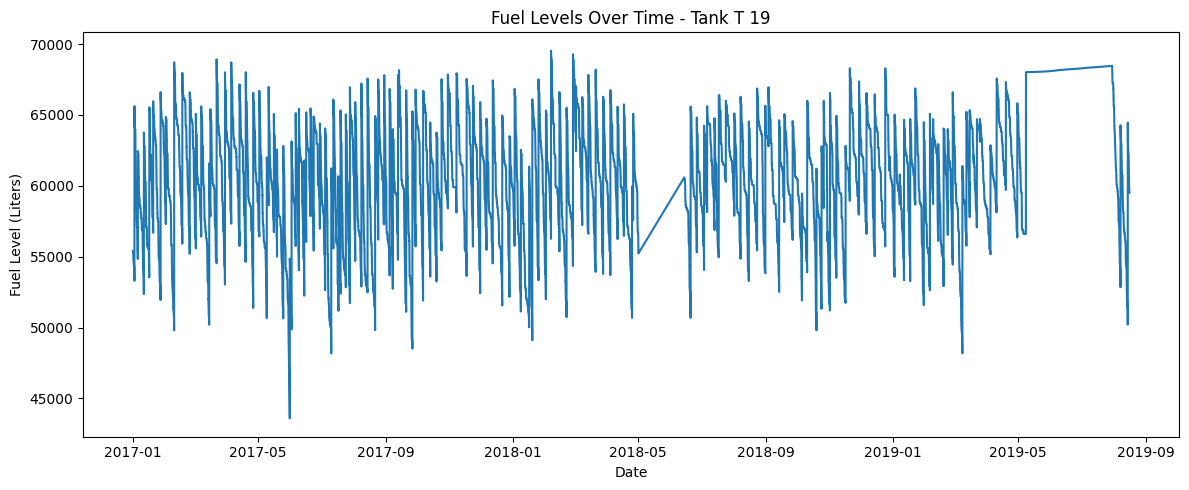

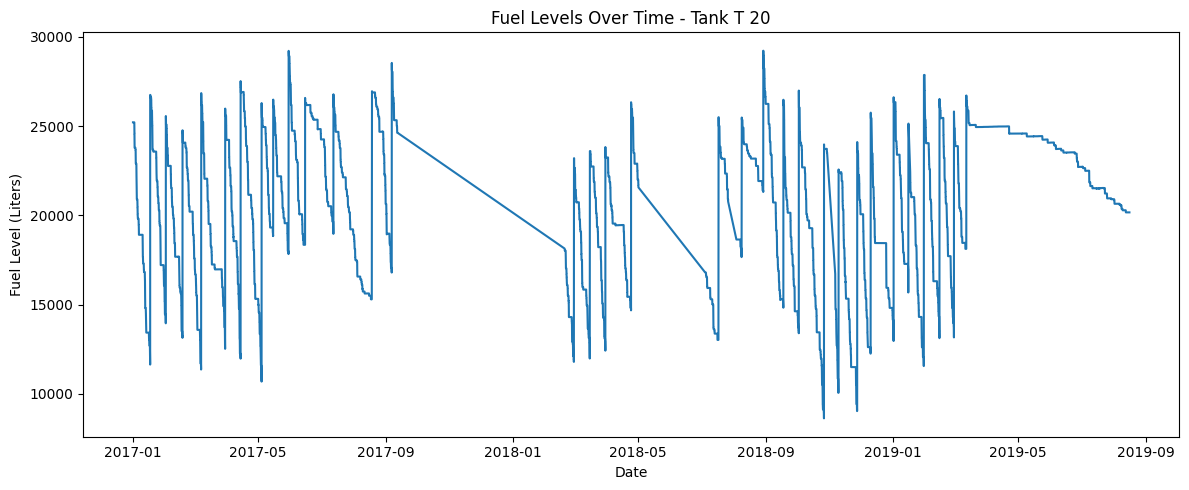

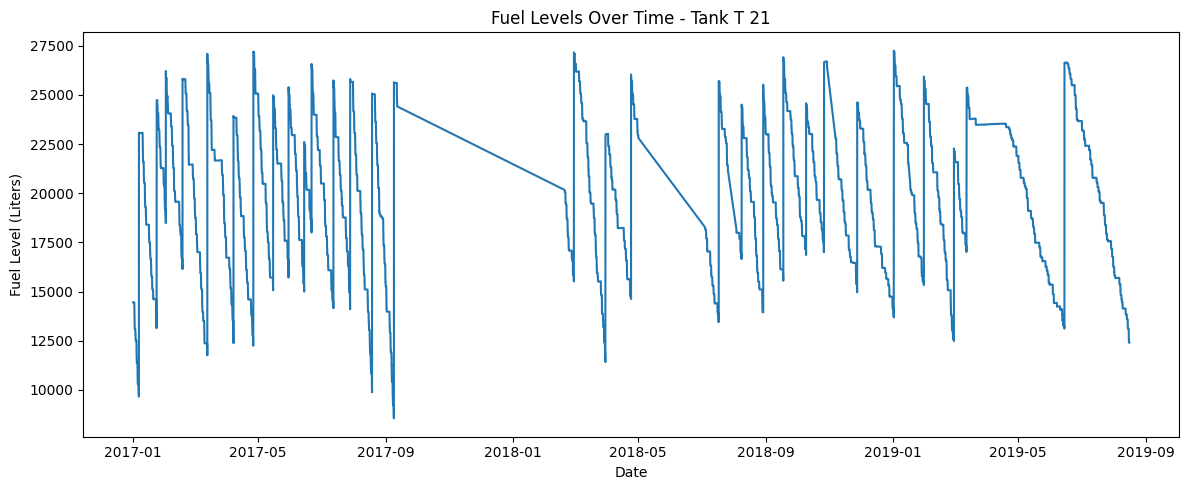

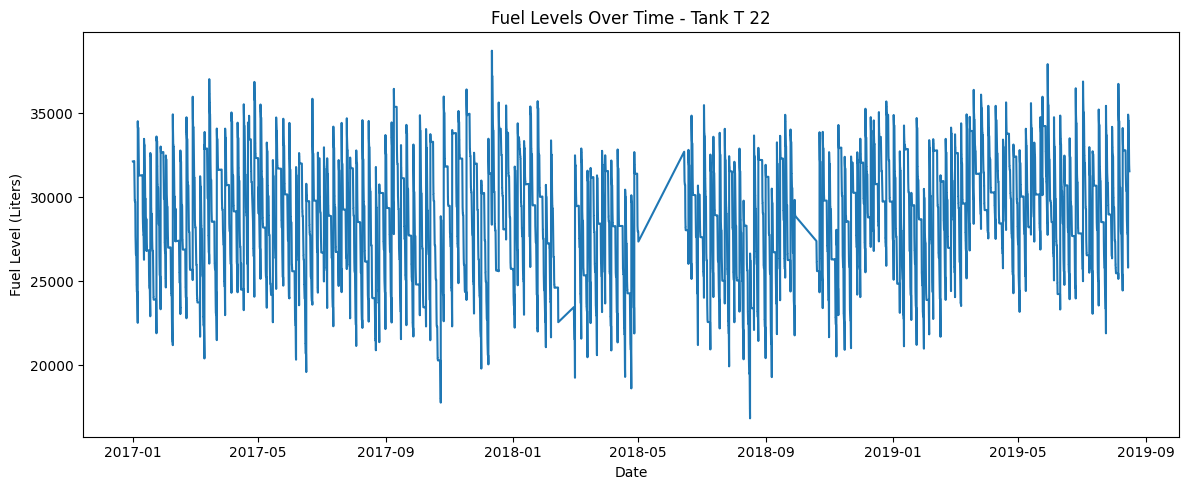

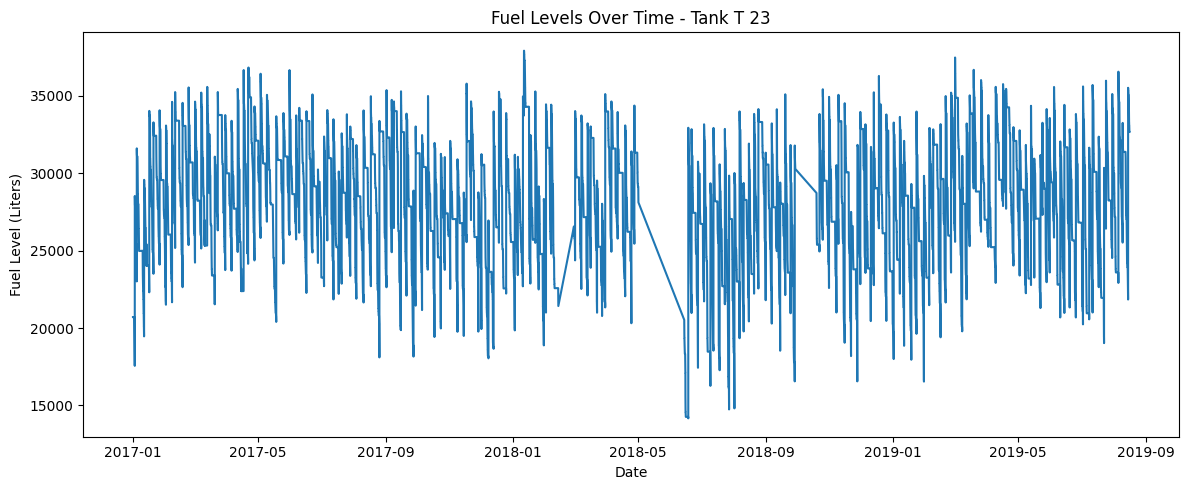

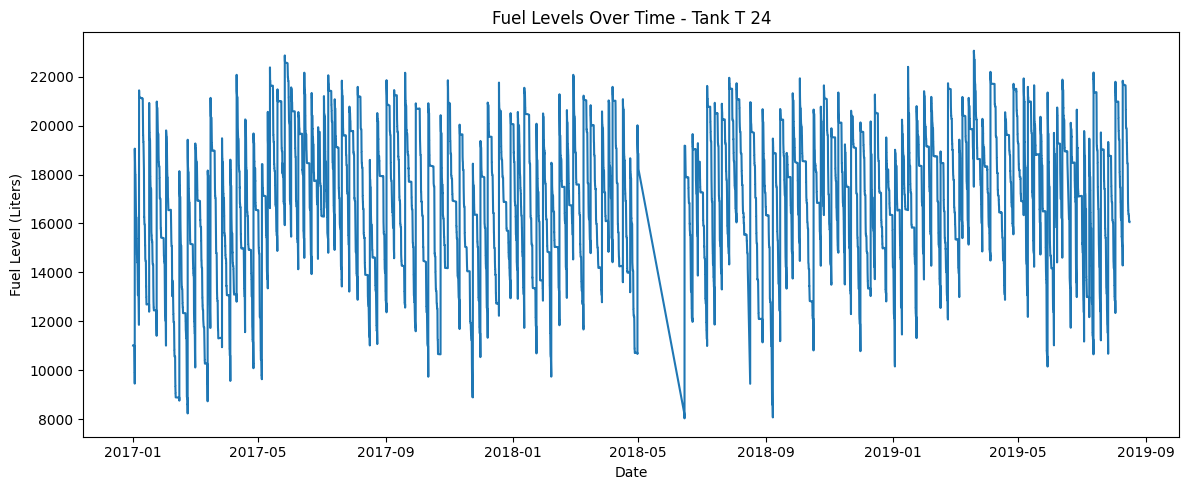

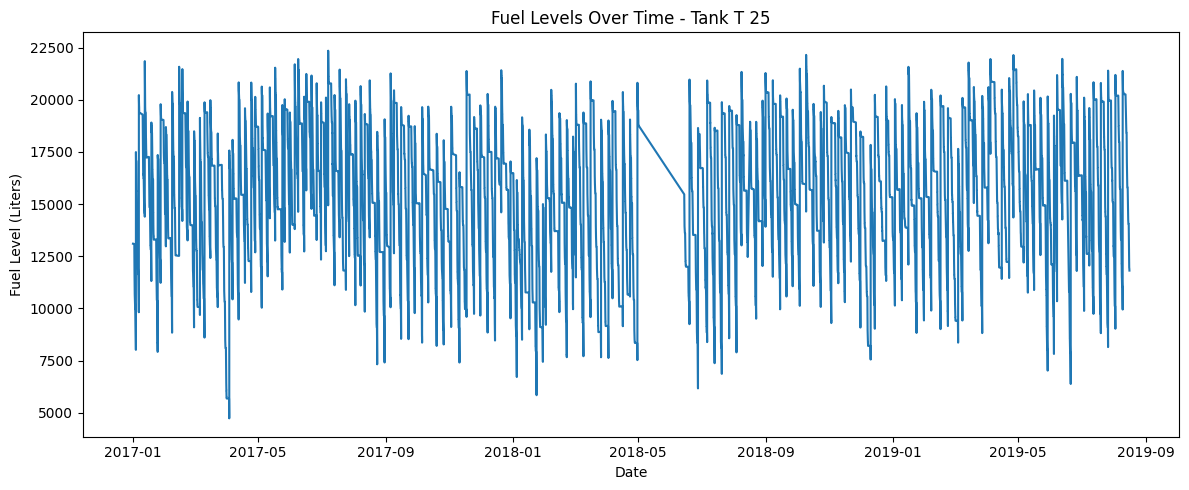

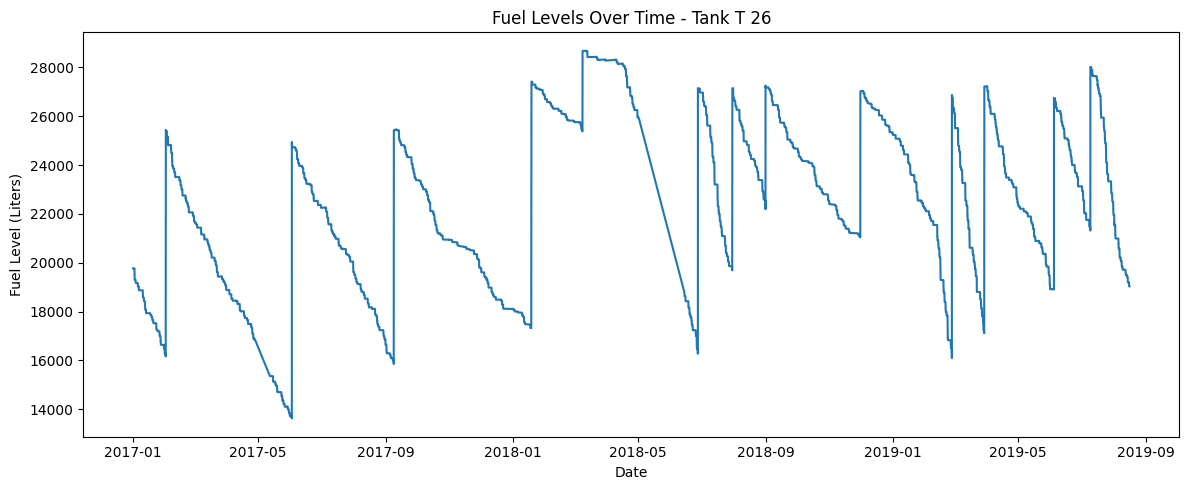

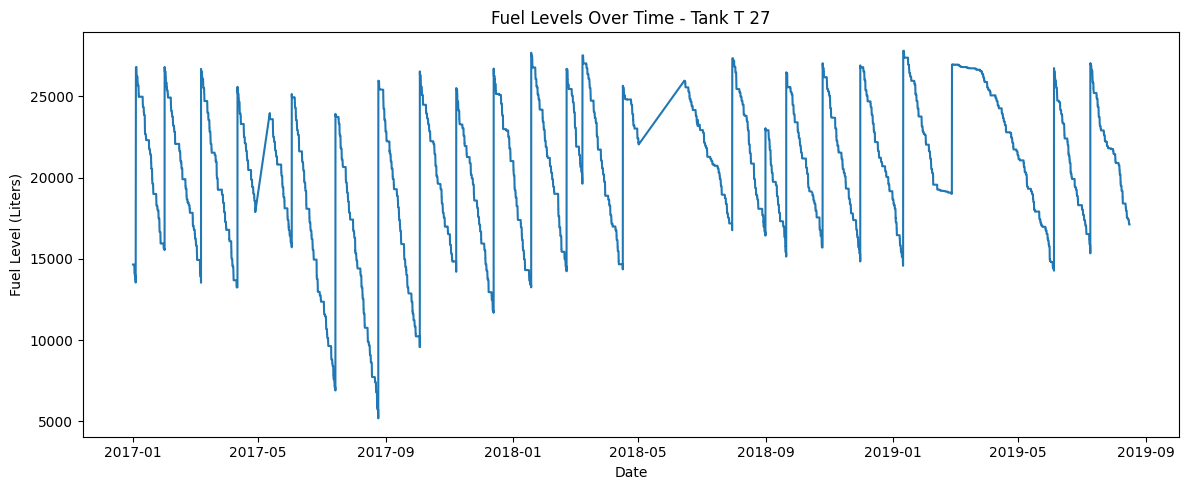

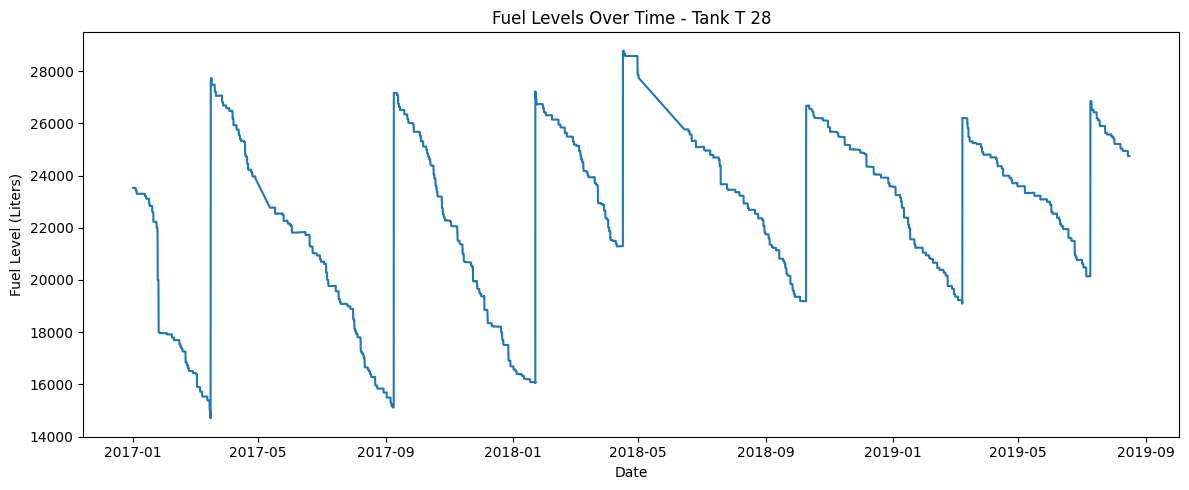

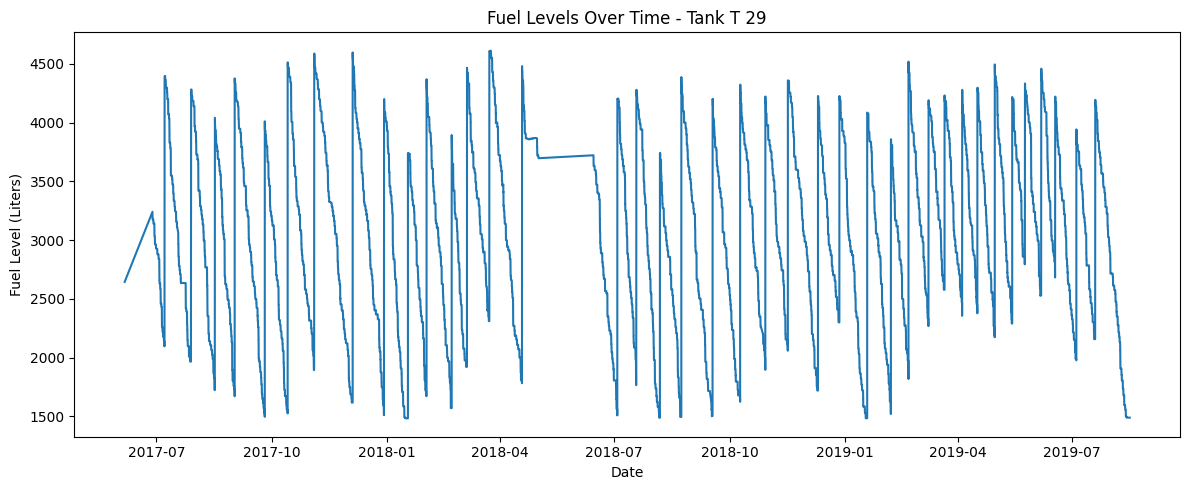

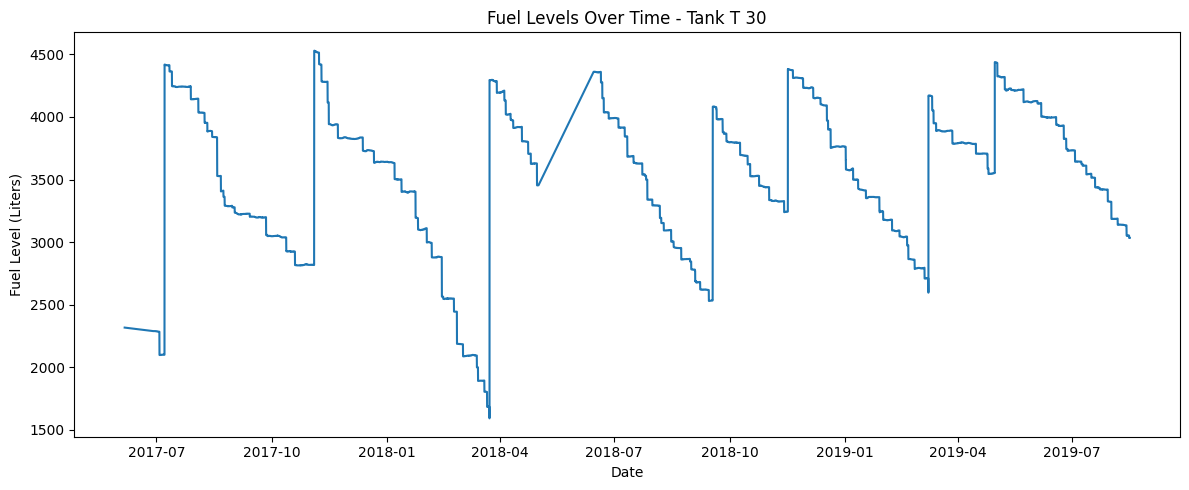

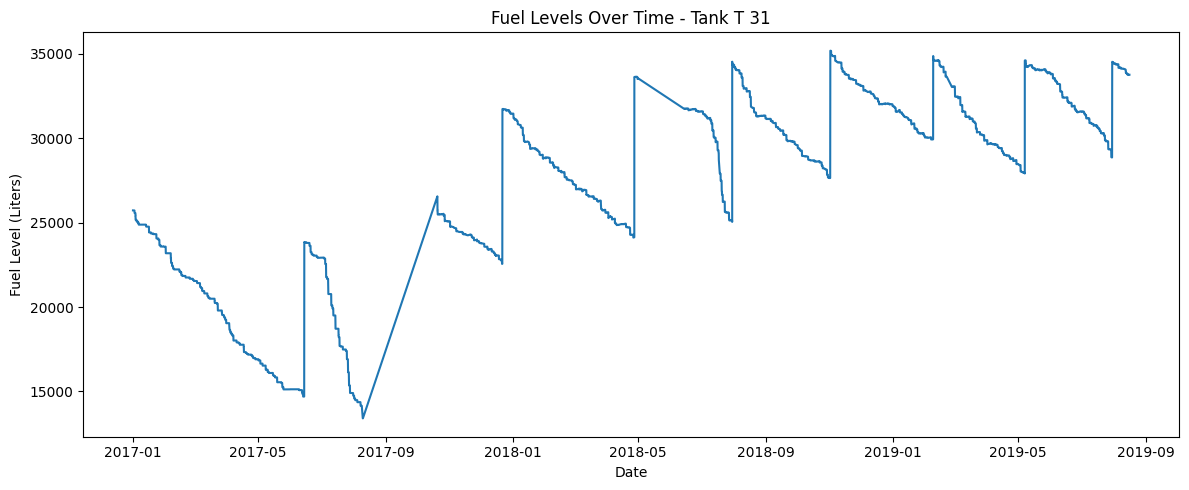

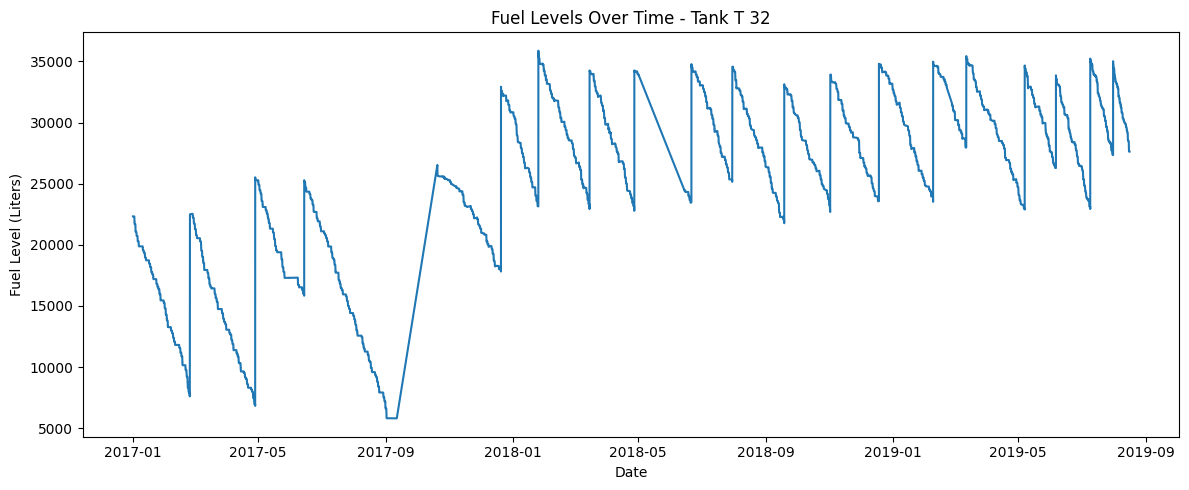

In [ ]:
#Ploting fuel levels over time for each tank
for tank_id in sorted(fuel_stations["Tank ID"].unique()):

    # Select records for each tank
    tank_data = fuel_stations[
        fuel_stations["Tank ID"] == tank_id
    ].sort_values("Time stamp")

    # Create the graph
    plt.figure(figsize=(12, 5))
    plt.plot(tank_data["Time stamp"], tank_data["Fuel Level"])

    plt.title(f"Fuel Levels Over Time - Tank {tank_id}")
    plt.xlabel("Date")
    plt.ylabel("Fuel Level (Liters)")
    plt.tight_layout()
    plt.show()


In [ ]:
#Sorting records by Tank ID and timestamp
fuel_stations = fuel_stations.sort_values(
    ["Tank ID", "Time stamp"]
)

# Calculating changes in fuel level for each tank
fuel_stations["Fuel Change"] = fuel_stations.groupby(
    "Tank ID"
)["Fuel Level"].diff()

# Checking the results for Tank T 12
fuel_stations[
    fuel_stations["Tank ID"] == "T 12"
][["Tank ID", "Time stamp", "Fuel Level", "Fuel Change"]].head(10)


,Tank ID,Time stamp,Fuel Level,Fuel Change
0,T 12,2017-01-01 00:10:00,27161.0,NaN
1,T 12,2017-01-01 00:25:00,27017.0,-144.0
2,T 12,2017-01-01 00:40:00,26934.0,-83.0
3,T 12,2017-01-01 00:55:00,26786.0,-148.0
4,T 12,2017-01-01 01:10:00,26748.0,-38.0
5,T 12,2017-01-01 01:25:00,26658.0,-90.0
6,T 12,2017-01-01 01:40:00,26658.0,0.0
7,T 12,2017-01-01 01:55:00,26661.0,3.0
8,T 12,2017-01-01 02:10:00,26661.0,0.0
9,T 12,2017-01-01 02:25:00,26661.0,0.0


In [ ]:
#Identify possible replenishment events
replenishments = fuel_stations[
    fuel_stations["Fuel Change"] >= 1000
]

#Counting possible replenishment events for each tank
replenishment_counts = replenishments.groupby("Tank ID").size()

print("Total possible replenishment events:", len(replenishments))
print(replenishment_counts)


Total possible replenishment events: 5251
Tank ID
T 10    342
T 11    522
T 12    712
T 13    185
T 14    538
T 15    378
T 16    266
T 17    381
T 18    256
T 19    266
T 20     67
T 21     58
T 22    293
T 23    304
T 24    199
T 25    280
T 26     25
T 27     59
T 28     15
T 29     39
T 30      6
T 31     16
T 32     44
dtype: int64


Using an initial threshold of 1,000 liters, I identified 5,251 possible replenishment-related increases across the tanks. However, these increases do not necessarily represent 5,251 separate deliveries, and further verification using invoice records is needed.

In [ ]:
#Checking for fuel levels below 20% of tank capacity
fuel_stations["Low Inventory"] = (
    fuel_stations["Fuel Level"] <
    fuel_stations["Tank Capacity"] * 0.20
)

#Counting low-inventory readings for each tank
low_inventory_counts = fuel_stations.groupby(
    "Tank ID"
)["Low Inventory"].sum()

print("Total low-inventory readings:",
      fuel_stations["Low Inventory"].sum())

print(low_inventory_counts)


Total low-inventory readings: 82933
Tank ID
T 10    27289
T 11       85
T 12      166
T 13    53273
T 14        0
T 15       11
T 16        0
T 17        0
T 18        0
T 19        0
T 20        0
T 21        0
T 22        0
T 23        0
T 24        0
T 25        9
T 26        0
T 27      112
T 28        0
T 29        0
T 30        0
T 31        0
T 32     1988
Name: Low Inventory, dtype: int64


To identify periods of low fuel inventory, I used a threshold of 20% of each tank's total capacity. Based on this threshold, I identified 82,933 low-inventory readings across the tanks. Tank T 13 had the highest number of low-inventory readings, with 53,273, followed by Tank T 10 with 27,289 and Tank T 32 with 1,988. These findings suggest that certain tanks experienced low fuel levels more frequently than others. However, the number of readings does not necessarily represent the number of separate low-inventory periods, since multiple readings could have occurred during the same period.

In [ ]:
#Calculating the percentage of low-inventory readings for each tank
low_inventory_percentage = fuel_stations.groupby(
    "Tank ID"
)["Low Inventory"].mean() * 100

#Displaying tanks with the highest percentages
print(low_inventory_percentage.sort_values(ascending=False))


Tank ID
T 13    63.613350
T 10    32.519037
T 32     2.400155
T 12     0.198119
T 27     0.130358
T 11     0.101378
T 15     0.013143
T 25     0.012447
T 14     0.000000
T 16     0.000000
T 17     0.000000
T 21     0.000000
T 18     0.000000
T 19     0.000000
T 20     0.000000
T 24     0.000000
T 23     0.000000
T 22     0.000000
T 26     0.000000
T 28     0.000000
T 29     0.000000
T 30     0.000000
T 31     0.000000
Name: Low Inventory, dtype: float64


To identify low-inventory periods, I used a threshold of 20% of each tank's total capacity. The results showed 82,933 low-inventory readings across the tanks. I then calculated the percentage of low-inventory readings for each tank to make the comparison more meaningful.

Tank T 13 had the highest percentage at 63.61%, followed by Tank T 10 at 32.52%. Tank T 32 had a much lower percentage at 2.40%, while most other tanks rarely or never fell below the threshold. These findings suggest that Tanks T 13 and T 10 may face greater inventory management challenges. However, the percentages represent recorded measurements rather than the actual duration of low-inventory periods.

In [ ]:
#Calculating low-inventory percentages by station and tank
station_inventory = fuel_stations.groupby(
    ["Gas Station Location", "Gas Station Name", "Tank ID"]
)["Low Inventory"].mean() * 100

#Displaying results from highest to lowest
print(station_inventory.sort_values(ascending=False))


Gas Station Location  Gas Station Name  Tank ID
1                     EastMount         T 13       63.613350
                                        T 10       32.519037
8                     Chappel           T 32        2.400155
1                     EastMount         T 12        0.198119
6                     Oakville          T 27        0.130358
1                     EastMount         T 11        0.101378
                                        T 15        0.013143
5                     Mountain View     T 25        0.012447
1                     EastMount         T 14        0.000000
2                     Eastgate          T 16        0.000000
                                        T 17        0.000000
3                     Central           T 21        0.000000
2                     Eastgate          T 18        0.000000
                                        T 19        0.000000
3                     Central           T 20        0.000000
5                     Mountain View  

After calculating the percentage of low-inventory readings for each tank, I grouped the results by gas station to identify which locations might face inventory management challenges. The results showed that EastMount (Station 1) had the highest percentages, particularly for Tank T 13 at 63.61% and Tank T 10 at 32.52%. This suggests that EastMount may face a greater risk of low fuel inventory compared to the other stations.

Chappel (Station 8) also had some low-inventory readings, with Tank T 32 recording 2.40%. On the other hand, stations such as Eastgate, Central, Chedoke, and Circle had no recorded fuel levels below the 20% threshold. However, these results alone do not necessarily mean that these stations manage their inventory more efficiently, since maintaining higher fuel levels could also result in unnecessary storage costs.

In [ ]:
#Calculating fuel levels as a percentage of tank capacity
fuel_stations["Capacity Percentage"] = (
    fuel_stations["Fuel Level"] /
    fuel_stations["Tank Capacity"]
) * 100

#Finding the lowest percentage recorded for each tank
stockout_risk = fuel_stations.groupby(
    ["Gas Station Location", "Gas Station Name", "Tank ID"]
)["Capacity Percentage"].min()

#Displaying results from lowest to highest
print(stockout_risk.sort_values())


Gas Station Location  Gas Station Name  Tank ID
1                     EastMount         T 12        6.417500
                                        T 10       11.207500
                                        T 13       12.502500
8                     Chappel           T 32       14.527500
1                     EastMount         T 15       17.035000
6                     Oakville          T 27       17.313333
1                     EastMount         T 11       18.645000
5                     Mountain View     T 25       18.944000
1                     EastMount         T 14       22.620000
3                     Central           T 21       28.493333
                                        T 20       28.760000
2                     Eastgate          T 17       29.555000
7                     Circle            T 29       29.680000
2                     Eastgate          T 18       30.227500
7                     Circle            T 30       31.840000
5                     Mountain View  

To further evaluate the risk of running out of fuel, I calculated the lowest recorded fuel level as a percentage of each tank's total capacity. The findings showed that EastMount (Station 1) appeared to face the greatest potential stockout risk, with Tank T 12 reaching as low as 6.42% of its capacity, followed by Tank T 10 at 11.21% and Tank T 13 at 12.50%.

Chappel (Station 8) and Oakville (Station 6) also had tanks that reached relatively low inventory levels, at 14.53% and 17.31%, respectively. However, these findings do not necessarily indicate that the stations experienced actual stockouts, since the analysis only considers tank capacity and does not yet account for daily fuel consumption or inventory held in other tanks of the same fuel type.

In [ ]:
#Sorting fuel readings by tank and timestamp
fuel_stations = fuel_stations.sort_values(
    ["Tank ID", "Time stamp"]
).copy()

#Calculating the time between readings in hours
fuel_stations["Hours Between Readings"] = (
    fuel_stations.groupby("Tank ID")["Time stamp"]
    .diff()
    .dt.total_seconds() / 3600
)

#Displaying the first 10 records for Tank T 12
fuel_stations[
    fuel_stations["Tank ID"] == "T 12"
][["Tank ID", "Time stamp", "Hours Between Readings"]].head(10)


,Tank ID,Time stamp,Hours Between Readings
0,T 12,2017-01-01 00:10:00,NaN
1,T 12,2017-01-01 00:25:00,0.25
2,T 12,2017-01-01 00:40:00,0.25
3,T 12,2017-01-01 00:55:00,0.25
4,T 12,2017-01-01 01:10:00,0.25
5,T 12,2017-01-01 01:25:00,0.25
6,T 12,2017-01-01 01:40:00,0.25
7,T 12,2017-01-01 01:55:00,0.25
8,T 12,2017-01-01 02:10:00,0.25
9,T 12,2017-01-01 02:25:00,0.25


In [ ]:
#Checking the time intervals between fuel readings
print(fuel_stations["Hours Between Readings"].describe())


count    1.859564e+06
mean     2.794205e-01
std      5.878147e+00
min      0.000000e+00
25%      2.500000e-01
50%      2.500000e-01
75%      2.500000e-01
max      3.851367e+03
Name: Hours Between Readings, dtype: float64


In [ ]:
#Checking for zero-hour intervals
zero_intervals = (
    fuel_stations["Hours Between Readings"] == 0
).sum()

#Checking for intervals longer than one hour
long_gaps = (
    fuel_stations["Hours Between Readings"] > 1
).sum()

print("Zero-hour intervals:", zero_intervals)
print("Intervals longer than one hour:", long_gaps)


Zero-hour intervals: 48
Intervals longer than one hour: 672


In [ ]:
#Recalculating fuel-level changes for each tank
fuel_stations["Fuel Change"] = fuel_stations.groupby(
    "Tank ID"
)["Fuel Level"].diff()

#Identifying intervals with decreasing fuel levels
fuel_stations["Consumption"] = (
    -fuel_stations["Fuel Change"]
).clip(lower=0)

#Identifying intervals with increasing fuel levels
fuel_stations["Possible Delivery"] = (
    fuel_stations["Fuel Change"] > 0
)

#Counting possible delivery intervals
print("Intervals with positive fuel changes:",
      fuel_stations["Possible Delivery"].sum())


Intervals with positive fuel changes: 51122


In [ ]:
#Selecting intervals suitable for estimating consumption
valid_intervals = fuel_stations[
    (fuel_stations["Hours Between Readings"] > 0) &
    (fuel_stations["Hours Between Readings"] <= 1) &
    (fuel_stations["Fuel Change"] <= 0)
].copy()

#Counting the intervals included in the analysis
print("Valid consumption intervals:", len(valid_intervals))
print("Excluded intervals:",
      len(fuel_stations) - len(valid_intervals))


Valid consumption intervals: 1807852
Excluded intervals: 51735


In [ ]:
#Calculating fuel consumption per hour
valid_intervals["Consumption Per Hour"] = (
    valid_intervals["Consumption"] /
    valid_intervals["Hours Between Readings"]
)

#Calculating average daily consumption for each tank
daily_consumption = valid_intervals.groupby(
    ["Gas Station Location", "Gas Station Name",
     "Tank ID", "Tank Type"]
)["Consumption Per Hour"].mean() * 24

#Displaying the results
print(daily_consumption)


Gas Station Location  Gas Station Name  Tank ID  Tank Type
1                     EastMount         T 10     U            3109.274157
                                        T 11     U            5107.185139
                                        T 12     D            5203.383422
                                        T 13     P            1672.638881
                                        T 14     U            3451.147101
                                        T 15     D            2587.636365
2                     Eastgate          T 16     U            1717.456397
                                        T 17     D            2505.678508
                                        T 18     U            1558.185422
                                        T 19     D            1768.661679
3                     Central           T 20     U             533.718110
                                        T 21     D             469.215419
4                     Chedoke           T 22     U   

In [ ]:
#3. Next: Calculate daily consumption by station and fuel type

#Calculating total consumption and valid hours for each tank
tank_consumption = valid_intervals.groupby(
    ["Gas Station Location", "Gas Station Name",
     "Tank ID", "Tank Type"]
).agg(
    Total_Consumption=("Consumption", "sum"),
    Total_Hours=("Hours Between Readings", "sum")
).reset_index()

#Calculating daily consumption for each tank
tank_consumption["Daily Consumption"] = (
    tank_consumption["Total_Consumption"] /
    tank_consumption["Total_Hours"]
) * 24

#Calculating daily consumption by station and fuel type
station_consumption = tank_consumption.groupby(
    ["Gas Station Location", "Gas Station Name", "Tank Type"]
)["Daily Consumption"].sum().reset_index()

print(station_consumption.to_string(index=False))


 Gas Station Location Gas Station Name Tank Type  Daily Consumption
                    1        EastMount         D        7707.286782
                    1        EastMount         P        1651.620399
                    1        EastMount         U       11641.307308
                    2         Eastgate         D        4250.990497
                    2         Eastgate         U        3256.666650
                    3          Central         D         468.925843
                    3          Central         U         533.511858
                    4          Chedoke         D        2148.114538
                    4          Chedoke         U        1949.576067
                    5    Mountain View         D        1086.692277
                    5    Mountain View         U        1594.697751
                    6         Oakville         D          73.055505
                    6         Oakville         U         453.702488
                    7           Circle         D

Write your methodology and limitations:
......